# 04 — NLP y Pipelines: clasificación de sentimientos

**Objetivo:** aprender cómo se representan textos numéricamente con Bag of Words y TF-IDF, y después integrar un vectorizador y un clasificador mediante `Pipeline` y `GridSearchCV`.


## 1. Conocer nuestros textos

Tenemos tres etiquetas: **positivo**, **negativo** y **neutral**. Explorá el DataFrame y observá la distribución de etiquetas.

In [125]:
import pandas as pd

datos = [
    ("Me encanta esta tecnología", "positivo"),
    ("Esta herramienta me ayuda mucho", "positivo"),
    ("Qué buena noticia sobre inteligencia artificial", "positivo"),
    ("Me gustan las mejoras del sistema", "positivo"),
    ("La nueva función es excelente", "positivo"),
    ("Estoy contenta con los resultados", "positivo"),
    ("No me gusta esta aplicación", "negativo"),
    ("Esta actualización funciona mal", "negativo"),
    ("Qué pésima experiencia de usuario", "negativo"),
    ("El sistema falla constantemente", "negativo"),
    ("Estoy decepcionada con esta herramienta", "negativo"),
    ("La respuesta fue muy mala", "negativo"),
    ("Se publicó una actualización hoy", "neutral"),
    ("La empresa presentó un modelo nuevo", "neutral"),
    ("El informe menciona inteligencia artificial", "neutral"),
    ("Hay una conferencia sobre tecnología", "neutral"),
    ("El sistema tiene tres versiones", "neutral"),
    ("La noticia fue publicada esta mañana", "neutral"),
]

df = pd.DataFrame(datos, columns=["texto", "sentimiento"])
df.head()


,texto,sentimiento
0,Me encanta esta tecnología,positivo
1,Esta herramienta me ayuda mucho,positivo
2,Qué buena noticia sobre inteligencia artificial,positivo
3,Me gustan las mejoras del sistema,positivo
4,La nueva función es excelente,positivo


## 2. Bag of Words — `CountVectorizer`

Bag of Words (bolsa de palabras) es una técnica que permite representar textos mediante números.
La idea es sencilla: registramos qué palabras aparecen en cada texto y cuántas veces aparecen.
Por ejemplo, imaginemos estos documentos:
- Documento 1: «Me gusta Python»
- Documento 2: «Me gusta Java»
- Documento 3: «Python es útil»

Podemos construir esta matriz:

|Documento|es|gusta|java|me|python|útil|
|--|--|--|--|--|--|--|
|1|0|1|0|1|1|0|
|2|0|1|1|1|0|0|
|3|1|0|0|0|1|1|

Cada fila representa un documento y cada columna representa una palabra del vocabulario.
Los números indican cuántas veces aparece cada palabra en cada documento.

Una limitación importante: Bag of Words no conserva el orden de las palabras. Por ejemplo, «perro muerde hombre» y «hombre muerde perro» producirían la misma representación si utilizamos las mismas reglas de tokenización.

In [126]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizador = CountVectorizer()

X_bow = vectorizador.fit_transform(df["texto"].head(5))

CountVectorizer() crea el objeto encargado de construir el vocabulario y transformar los textos.

fit_transform() realiza dos operaciones:
- fit: aprende qué palabras forman parte del vocabulario a partir de los textos que recibe.
- transform: convierte esos textos en una matriz de números utilizando el vocabulario aprendido.

In [127]:
print(vectorizador.get_feature_names_out())
print('-------------------------------------------------------------')
print(X_bow.shape)
print('-------------------------------------------------------------')
print(X_bow.toarray()) ## para cada fila me fijo cuantas veces aparecio cada palabra

['artificial' 'ayuda' 'buena' 'del' 'encanta' 'es' 'esta' 'excelente'
 'función' 'gustan' 'herramienta' 'inteligencia' 'la' 'las' 'me' 'mejoras'
 'mucho' 'noticia' 'nueva' 'qué' 'sistema' 'sobre' 'tecnología']
-------------------------------------------------------------
(5, 23)
-------------------------------------------------------------
[[0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1]
 [0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0]
 [1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0 1 0]
 [0 0 0 1 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0]
 [0 0 0 0 0 1 0 1 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0]]


In [128]:
df_bow = pd.DataFrame(
    X_bow.toarray(),
    columns=vectorizador.get_feature_names_out()
)

df_bow

,artificial,ayuda,buena,del,encanta,es,esta,excelente,función,gustan,...,las,me,mejoras,mucho,noticia,nueva,qué,sistema,sobre,tecnología
0,0,0,0,0,1,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,1
1,0,1,0,0,0,0,1,0,0,0,...,0,1,0,1,0,0,0,0,0,0
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,1,0
3,0,0,0,1,0,0,0,0,0,1,...,1,1,1,0,0,0,0,1,0,0
4,0,0,0,0,0,1,0,1,1,0,...,0,0,0,0,0,1,0,0,0,0


Lo importante: cada palabra se convierte en una característica numérica que después puede utilizar un clasificador.

- me: aparece en tres textos.
- excelente: aparece en uno solo.
Para CountVectorizer, ambas palabras se representan de la misma manera cuando aparecen una vez: con un 1.
Sin embargo, para clasificar sentimientos, podría ser más informativa la palabra excelente que la palabra me.
Bag of Words no realiza esa distinción por sí mismo: solamente cuenta las apariciones.

## 3. TF-IDF — `TfidfVectorizer`

TF-IDF considera tanto la frecuencia de una palabra en un documento como su frecuencia en el conjunto de documentos. Así puede asignar un peso menor a palabras que aparecen en muchos documentos.

In [129]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizador_tfidf = TfidfVectorizer()

X_tfidf = vectorizador_tfidf.fit_transform(df["texto"].head(5))

In [130]:
df_tfidf = pd.DataFrame(
    X_tfidf.toarray(),
    columns=vectorizador_tfidf.get_feature_names_out()
)

df_tfidf

,artificial,ayuda,buena,del,encanta,es,esta,excelente,función,gustan,...,las,me,mejoras,mucho,noticia,nueva,qué,sistema,sobre,tecnología
0,0.000000,0.000000,0.000000,0.000000,0.568014,0.000000,0.458270,0.000000,0.000000,0.000000,...,0.000000,0.380406,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.568014
1,0.000000,0.493899,0.000000,0.000000,0.000000,0.000000,0.398475,0.000000,0.000000,0.000000,...,0.000000,0.330770,0.000000,0.493899,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.408248,0.000000,0.408248,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.408248,0.000000,0.408248,0.000000,0.408248,0.000000
3,0.000000,0.000000,0.000000,0.428411,0.000000,0.000000,0.000000,0.000000,0.000000,0.428411,...,0.428411,0.286912,0.428411,0.000000,0.000000,0.000000,0.000000,0.428411,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.447214,0.000000,0.447214,0.447214,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.447214,0.000000,0.000000,0.000000,0.000000


TF-IDF combina dos conceptos:
1. TF (Term Frequency)
Considera cuántas veces aparece una palabra dentro de un documento.
2. IDF (Inverse Document Frequency)
Considera qué tan frecuente es esa palabra entre todos los documentos.
La idea es que una palabra que aparece en muchísimos documentos suele recibir un peso menor que otra menos frecuente, manteniendo iguales los demás factores.

¿Y por qué nos interesa esto para el TP?
Imaginá que estamos clasificando tweets.
Palabras como inteligencia, artificial o tecnología podrían aparecer en muchísimos tweets, independientemente de su sentimiento.
En cambio, expresiones como excelente, terrible o decepcionante podrían aportar información más útil para distinguir sentimientos.
TF-IDF puede ayudar a destacar palabras menos comunes, aunque no sabe cuáles son positivas o negativas. Eso lo aprende después el clasificador.

## 4. Separar entrenamiento y prueba

In [131]:
from sklearn.model_selection import train_test_split

X = df["texto"]
y = df["sentimiento"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(y_train.value_counts())
print(y_test.value_counts())

sentimiento
negativo    5
neutral     5
positivo    4
Name: count, dtype: int64
sentimiento
positivo    2
neutral     1
negativo    1
Name: count, dtype: int64


## 5. Construir un `Pipeline`

### Primero, que es lo que viene a resolver?

Supongamos que queremos clasificar tweets como positivos, negativos o neutrales.
Ya conocés TfidfVectorizer y sabés que necesitamos un modelo para clasificarlos.
Sin Pipeline haríamos esto:

```py
# Paso 1: Crear el vectorizador
vectorizador = TfidfVectorizer()

# Paso 2: Transformar los textos de entrenamiento
X_train_tfidf = vectorizador.fit_transform(X_train)

# Paso 3: Crear el modelo
modelo = LogisticRegression()

# Paso 4: Entrenar el modelo con los textos transformados
modelo.fit(X_train_tfidf, y_train)
```

Hasta acá, perfecto. ¡No necesitamos ningún Pipeline!
Ahora queremos predecir el sentimiento de nuevos tweets.

```py
# Paso 5: Transformar los textos de prueba
X_test_tfidf = vectorizador.transform(X_test)

# Paso 6: Predecir
y_pred = modelo.predict(X_test_tfidf)
```

Esto es completamente válido.
Per: tenemos dos objetos diferentes que debemos manejar correctamente.
- vectorizador: sabe transformar textos en números.
- modelo: sabe clasificar esos números.
Cada vez que queramos predecir el sentimiento de un texto nuevo, tenemos que acordarnos de pasarlo primero por el vectorizador.

### Ahora, para resolverlo usando un pipeline:

```py
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression())
])
```

Acabamos de decirle a Scikit-Learn:
Cuando entrenes, primero transformá los textos con TF-IDF y después entrená Logistic Regression. Cuando predigas, primero transformá el texto con el TF-IDF ya entrenado y después pedile la predicción al clasificador.

```py
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
```

In [132]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(random_state=42))
])

## 6. Entrenar, predecir y evaluar

In [133]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negativo','neutral','positivo']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [134]:
y_pred = pipeline.predict(X_test)
print(y_pred)

['negativo' 'positivo' 'negativo' 'negativo']


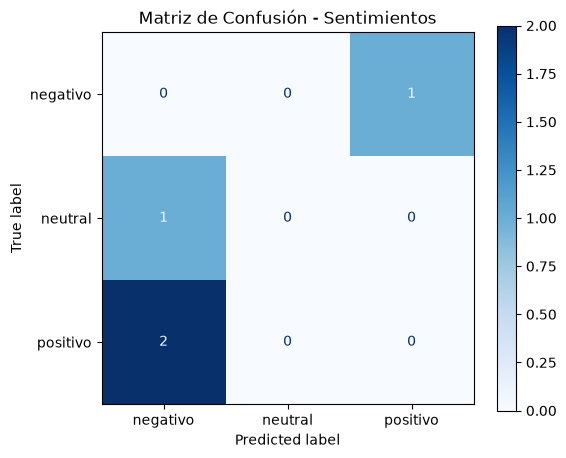

In [135]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    pipeline, X_test, y_test, cmap="Blues", ax=ax
)

plt.title("Matriz de Confusión - Sentimientos")
plt.show()

In [136]:
from sklearn.metrics import accuracy_score

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

    negativo       0.00      0.00      0.00       1.0
     neutral       0.00      0.00      0.00       1.0
    positivo       0.00      0.00      0.00       2.0

    accuracy                           0.00       4.0
   macro avg       0.00      0.00      0.00       4.0
weighted avg       0.00      0.00      0.00       4.0



## 7. `Pipeline` + `GridSearchCV`

In [137]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.1, 1, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring="f1_macro"
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitti

In [138]:
print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor Macro F1 promedio:", grid.best_score_)
print("Mejor modelo:", grid.best_estimator_)

Mejores hiperparámetros: {'classifier__C': 10}
Mejor Macro F1 promedio: 0.08888888888888889
Mejor modelo: Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('classifier', LogisticRegression(C=10, random_state=42))])


## 8. Conclusiones y transferencia al TP

Explicá:

- Qué información conserva Bag of Words y qué cambia TF-IDF.
- Qué automatiza `Pipeline`.
- Por qué combinar `Pipeline` y `GridSearchCV` ayuda a prevenir *data leakage*.
- Qué habría que revisar antes de procesar tweets reales en español: URLs, menciones, hashtags, emojis, negaciones y balance de clases.

**No reemplazar el dataset real del TP por estos ejemplos inventados.**